<a href="https://colab.research.google.com/github/josephdruben-hue/nyc-taxi-demand-analysis/blob/main/NYC_Taxi_Demand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Modeling of NYC Taxi Demand Using High-Volume Parquet Datasets

This project builds a scalable pipeline to analyze and forecast NYC taxi demand using large-scale trip record data. Raw Parquet files are processed using PySpark to aggregate trips at the zone-hour level, after which Python is used to explore patterns and develop a basic forecasting approach. The results are presented through a Power BI dashboard that highlights demand trends, high-traffic areas, and model outputs. Overall, the project focuses on combining distributed data processing with practical analytics to better understand urban transportation demand.

## Step 1: Connect to and load Parquet files using PySpark

In [ ]:
%pip install pyspark

Initial setup:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName('TaxiData').getOrCreate()

Load trips data:

In [ ]:
yellow_taxi_path = '/content/drive/My Drive/bia_678_final/data/yellow_taxi_trips'

yellow_taxi_df = spark.read.parquet(yellow_taxi_path)

green_taxi_path = '/content/drive/My Drive/bia_678_final/data/green_taxi_trips'

green_taxi_df = spark.read.parquet(green_taxi_path)

fhvhv_path = '/content/drive/My Drive/bia_678_final/data/fhvhv_trips'

fhvhv_df = spark.read.parquet(fhvhv_path)


## Step 2: Combine, clean, and enrich trips data

In [ ]:
from pyspark.sql import functions as F

yellow_trips_std = yellow_taxi_df.select(
    F.lit('yellow_taxi').alias('trip_type'),
    F.col('tpep_pickup_datetime').alias('pickup_timestamp'),
    F.col('tpep_dropoff_datetime').alias('dropoff_timestamp'),
    F.col('PULocationID').alias('pickup_location'),
    F.col('DOLocationID').alias('dropoff_location'),
    F.col('fare_amount').alias('base_fare'),
    F.col('trip_distance').alias('trip_distance'),
    F.col('congestion_surcharge')
)

green_trips_std = green_taxi_df.select(
    F.lit('green_taxi').alias('trip_type'),
    F.col('lpep_pickup_datetime').alias('pickup_timestamp'),
    F.col('lpep_dropoff_datetime').alias('dropoff_timestamp'),
    F.col('PULocationID').alias('pickup_location'),
    F.col('DOLocationID').alias('dropoff_location'),
    F.col('fare_amount').alias('base_fare'),
    F.col('trip_distance').alias('trip_distance'),
    F.col('congestion_surcharge')
)

fhvhv_trips_std = fhvhv_df.select(
    F.when(F.col('hvfhs_license_num') == 'HV0002', 'juno')
     .when(F.col('hvfhs_license_num') == 'HV0003', 'uber')
     .when(F.col('hvfhs_license_num') == 'HV0004', 'via')
     .when(F.col('hvfhs_license_num') == 'HV0005', 'lyft')
     .otherwise('other')
     .alias('trip_type'),
    F.col('pickup_datetime').alias('pickup_timestamp'),
    F.col('dropoff_datetime').alias('dropoff_timestamp'),
    F.col('PULocationID').alias('pickup_location'),
    F.col('DOLocationID').alias('dropoff_location'),
    F.col('base_passenger_fare').alias('base_fare'),
    F.col('trip_miles').alias('trip_distance'),
    F.col('congestion_surcharge')
)

trips = yellow_trips_std.unionByName(green_trips_std).unionByName(fhvhv_trips_std)

Examine combined trips data:

In [ ]:
trips.printSchema()
trips.show(5)

root
 |-- trip_type: string (nullable = false)
 |-- pickup_timestamp: timestamp_ntz (nullable = true)
 |-- dropoff_timestamp: timestamp_ntz (nullable = true)
 |-- pickup_location: integer (nullable = true)
 |-- dropoff_location: integer (nullable = true)
 |-- base_fare: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)

+-----------+-------------------+-------------------+---------------+----------------+---------+-------------+--------------------+
|  trip_type|   pickup_timestamp|  dropoff_timestamp|pickup_location|dropoff_location|base_fare|trip_distance|congestion_surcharge|
+-----------+-------------------+-------------------+---------------+----------------+---------+-------------+--------------------+
|yellow_taxi|2025-05-01 00:07:06|2025-05-01 00:24:15|            140|             202|     18.4|          3.7|                 2.5|
|yellow_taxi|2025-05-01 00:07:44|2025-05-01 00:14:27|            234|         

In [ ]:
trips.groupBy('trip_type').count().show()

+-----------+---------+
|  trip_type|    count|
+-----------+---------+
|yellow_taxi| 48722602|
| green_taxi|   591375|
|       lyft| 67600138|
|       uber|175989546|
+-----------+---------+



Confirm fhvhv dataset genuinely only contains Uber + Lyft:

In [ ]:
fhvhv_df.select('hvfhs_license_num').distinct().show()

+-----------------+
|hvfhs_license_num|
+-----------------+
|           HV0005|
|           HV0003|
+-----------------+



Load zone data:

In [ ]:
zones_path = '/content/drive/My Drive/bia_678_final/data/zones/taxi_zone_lookup.csv'

zones_df = spark.read \
    .option('header', 'true') \
    .option('inferSchema', 'true') \
    .csv(zones_path)

zones_df.show(5)
zones_df.printSchema()

+----------+-------------+--------------------+------------+
|LocationID|      Borough|                Zone|service_zone|
+----------+-------------+--------------------+------------+
|         1|          EWR|      Newark Airport|         EWR|
|         2|       Queens|         Jamaica Bay|   Boro Zone|
|         3|        Bronx|Allerton/Pelham G...|   Boro Zone|
|         4|    Manhattan|       Alphabet City| Yellow Zone|
|         5|Staten Island|       Arden Heights|   Boro Zone|
+----------+-------------+--------------------+------------+
only showing top 5 rows
root
 |-- LocationID: integer (nullable = true)
 |-- Borough: string (nullable = true)
 |-- Zone: string (nullable = true)
 |-- service_zone: string (nullable = true)



Add zone data to trips table:

In [ ]:
from pyspark.sql import functions as F

# Create aliased versions of zones for pickup and dropoff
pickup_zones = zones_df.select(
    F.col('LocationID').alias('pickup_location'),
    F.col('Borough').alias('pickup_borough'),
    F.col('Zone').alias('pickup_zone'),
    F.col('service_zone').alias('pickup_service_zone')
)

dropoff_zones = zones_df.select(
    F.col('LocationID').alias('dropoff_location'),
    F.col('Borough').alias('dropoff_borough'),
    F.col('Zone').alias('dropoff_zone'),
    F.col('service_zone').alias('dropoff_service_zone')
)

# Join to trips
trips_enriched = trips \
    .join(pickup_zones, on='pickup_location', how='left') \
    .join(dropoff_zones, on='dropoff_location', how='left')

# Drop original ID columns
trips_enriched = trips_enriched.drop('pickup_location', 'dropoff_location')

# Preview
trips_enriched.printSchema()
trips_enriched.show(5)

root
 |-- trip_type: string (nullable = false)
 |-- pickup_timestamp: timestamp_ntz (nullable = true)
 |-- dropoff_timestamp: timestamp_ntz (nullable = true)
 |-- base_fare: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- pickup_borough: string (nullable = true)
 |-- pickup_zone: string (nullable = true)
 |-- pickup_service_zone: string (nullable = true)
 |-- dropoff_borough: string (nullable = true)
 |-- dropoff_zone: string (nullable = true)
 |-- dropoff_service_zone: string (nullable = true)

+-----------+-------------------+-------------------+---------+-------------+--------------------+--------------+-----------------+-------------------+---------------+--------------------+--------------------+
|  trip_type|   pickup_timestamp|  dropoff_timestamp|base_fare|trip_distance|congestion_surcharge|pickup_borough|      pickup_zone|pickup_service_zone|dropoff_borough|        dropoff_zone|dropoff_service_zone|


Remove extreme outliers and errors:

In [ ]:
before_count = trips_enriched.count()

trips_enriched = trips_enriched.filter(
    (F.col('trip_distance') < 1000)
)

after_count = trips_enriched.count()

removed_count = before_count - after_count

print(f'Records removed: {removed_count}')
print(f'Records remaining: {after_count}')

Records removed: 2232
Records remaining: 292901429


**Data Cleaning Note**

The main cleaning step removes extreme trip-distance values that are unlikely to represent normal NYC taxi or rideshare activity. This helps reduce the impact of obvious outliers before aggregation and modeling.

However, this is not a complete data-quality framework. Additional checks could improve the pipeline, such as validating timestamp ranges, removing impossible trip durations, checking for missing or invalid pickup/dropoff zones, and applying stricter distance thresholds by service type. For this project, the cleaning process focuses on removing the most obvious extreme values while keeping the pipeline simple and reproducible.

## Step 3: Initial visualizations for demand patterns by geography & time

In [ ]:
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

1. Trips by hour of day

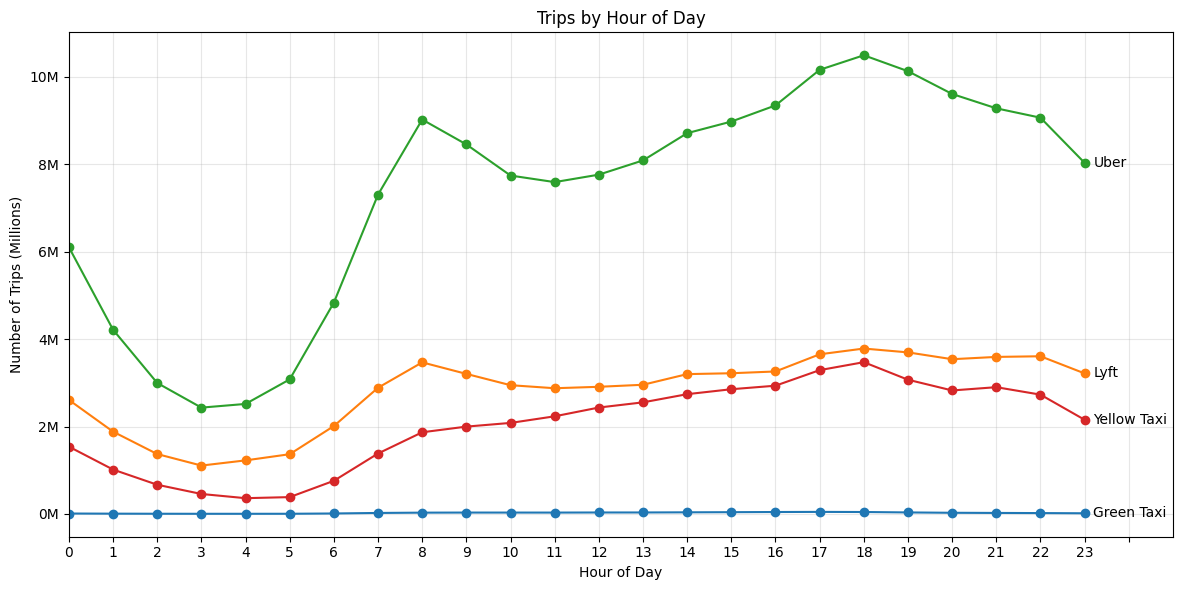

In [ ]:
hourly_trips_spark = (
    trips_enriched
    .withColumn('pickup_hour', F.hour('pickup_timestamp'))
    .groupBy('pickup_hour', 'trip_type')
    .agg(F.count('*').alias('trip_count'))
    .orderBy('pickup_hour', 'trip_type')
)

hourly_trips_pd = hourly_trips_spark.toPandas()

hourly_pivot = (
    hourly_trips_pd
    .pivot(index='pickup_hour', columns='trip_type', values='trip_count')
    .fillna(0)
    .sort_index()
)

label_map = {
    'green_taxi': 'Green Taxi',
    'yellow_taxi': 'Yellow Taxi',
    'uber': 'Uber',
    'lyft': 'Lyft'
}

plt.figure(figsize=(12, 6))

for col in hourly_pivot.columns:
    x = hourly_pivot.index
    y = hourly_pivot[col]

    plt.plot(x, y, marker='o')

    plt.text(
        x[-1] + 0.2,
        y.iloc[-1],
        label_map.get(col, col),
        fontsize=10,
        verticalalignment='center'
    )

plt.title('Trips by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips (Millions)')
plt.grid(True, alpha=0.3)

ax = plt.gca()
ax.set_xticks(range(0, 25))
ax.set_xticklabels([str(i) if i < 24 else '' for i in range(25)])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x/1e6)}M'))

plt.xlim(0, 25)
plt.tight_layout()
plt.show()

2. Trips by pickup borough

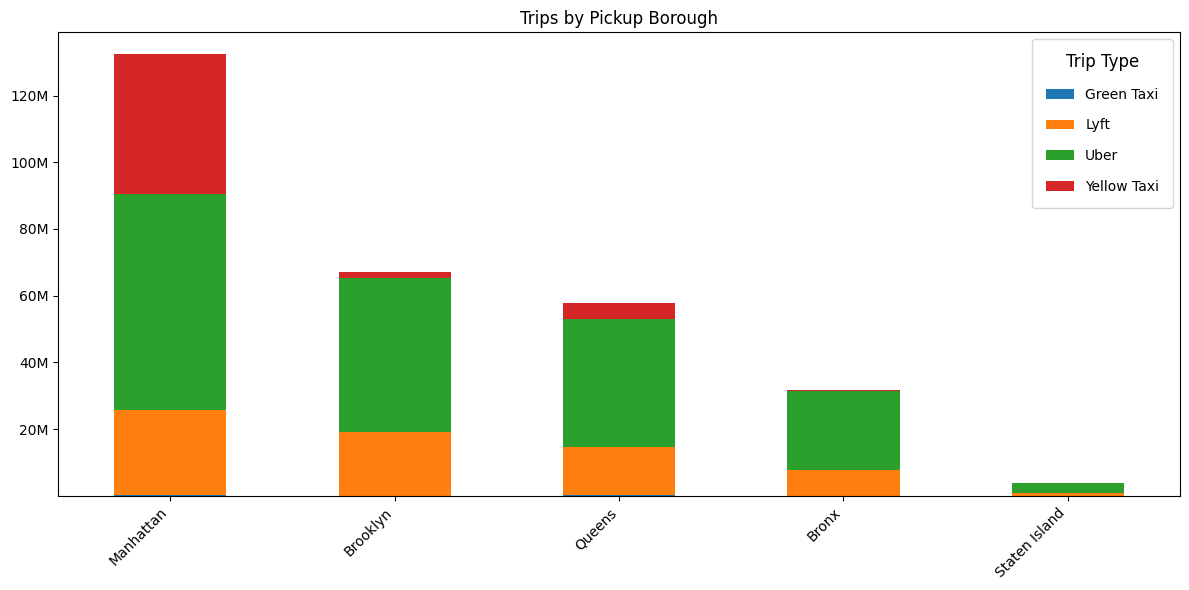

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Filter out unwanted "boroughs"
borough_trips_spark = (
    trips_enriched
    .filter(~F.col('pickup_borough').isin('EWR', 'Unknown', 'N/A'))
    .groupBy('pickup_borough', 'trip_type')
    .agg(F.count('*').alias('trip_count'))
    .orderBy('pickup_borough', 'trip_type')
)

borough_trips_pd = borough_trips_spark.toPandas()

borough_pivot = (
    borough_trips_pd
    .pivot(index='pickup_borough', columns='trip_type', values='trip_count')
    .fillna(0)
)

borough_order = ['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']
borough_pivot = borough_pivot.reindex([b for b in borough_order if b in borough_pivot.index])

# Rename legend labels
label_map = {
    'green_taxi': 'Green Taxi',
    'yellow_taxi': 'Yellow Taxi',
    'uber': 'Uber',
    'lyft': 'Lyft'
}

borough_pivot = borough_pivot.rename(columns=label_map)

# Plot
ax = borough_pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

# Format Y-axis with K / M / B
def format_large_numbers(x, _):
    if x >= 1e9:
        return f'{x / 1e9:.1f}B'
    elif x >= 1e6:
        return f'{x / 1e6:.0f}M'
    elif x >= 1e3:
        return f'{x / 1e3:.0f}K'
    else:
        return str(int(x))

ax.yaxis.set_major_formatter(ticker.FuncFormatter(format_large_numbers))

plt.title('Trips by Pickup Borough')

# Remove axis labels
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')

# Clean legend formatting
plt.legend(
    title='Trip Type',
    title_fontsize=12,
    fontsize=10,
    labelspacing=1.2,
    borderpad=1
)

plt.tight_layout()
plt.show()

## Step 4: Linear regression to predict hourly ride demand at the pickup zone level

Aggregate to zone-hour level:

In [ ]:
zone_hour_df = (
    trips_enriched
    .withColumn('date', F.to_date('pickup_timestamp'))
    .withColumn('hour', F.hour('pickup_timestamp'))
    .withColumn('day_of_week', F.dayofweek('pickup_timestamp'))  # 1=Sunday, 7=Saturday
    .groupBy('pickup_zone', 'date', 'hour', 'day_of_week')
    .agg(F.count('*').alias('trip_count'))
)

zone_hour_df.printSchema()
zone_hour_df.show(5)

root
 |-- pickup_zone: string (nullable = true)
 |-- date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- trip_count: long (nullable = false)

+--------------------+----------+----+-----------+----------+
|         pickup_zone|      date|hour|day_of_week|trip_count|
+--------------------+----------+----+-----------+----------+
|Upper East Side S...|2025-05-01|   0|          5|       188|
|West Chelsea/Huds...|2025-04-30|  23|          4|       372|
|TriBeCa/Civic Center|2025-05-01|   1|          5|       137|
|            Union Sq|2025-05-01|   4|          5|        48|
|          Greenpoint|2025-05-01|   6|          5|       206|
+--------------------+----------+----+-----------+----------+
only showing top 5 rows


Create lag features:

In [ ]:
from pyspark.sql.window import Window

window_spec = Window.partitionBy('pickup_zone').orderBy('date', 'hour')

zone_hour_df = (
    zone_hour_df
    .withColumn('prev_hour_demand', F.lag('trip_count', 1).over(window_spec))
    .withColumn('prev_day_same_hour_demand', F.lag('trip_count', 24).over(window_spec))
    .withColumn('prev_week_same_day_same_hour_demand', F.lag('trip_count', 168).over(window_spec))
)

# Drop nulls
zone_hour_df = zone_hour_df.dropna()

**Lag Feature Limitation**

The lag features are designed to represent recent and repeating demand patterns: the previous hour, the same hour on the previous day, and the same hour on the previous week. These features are useful because ride demand often follows strong short-term and weekly patterns.

One limitation is that the current implementation calculates lag values using ordered rows within each pickup zone. This assumes that each pickup zone has a continuous hourly time series. If some zone-hour combinations are missing, then a lag of 24 rows may not always perfectly represent the same hour on the previous day, and a lag of 168 rows may not always perfectly represent the same hour on the previous week.

A more robust future enhancement would create a complete pickup-zone × date × hour grid, fill missing trip counts with zero, and then calculate lag features from that complete time series. This would ensure that each lag feature is aligned to the correct timestamp.

Prepare features for regression:

In [ ]:
zone_hour_df_pd = zone_hour_df.toPandas()

zone_hour_df_pd = (
    zone_hour_df_pd
    .sort_values(['date', 'hour'])
    .reset_index(drop=True)
)

X = zone_hour_df_pd[
    [
        'pickup_zone',
        'hour',
        'day_of_week',
        'prev_hour_demand',
        'prev_day_same_hour_demand',
        'prev_week_same_day_same_hour_demand'
    ]
]

y = zone_hour_df_pd['trip_count']

X = pd.get_dummies(X, columns=['pickup_zone'], drop_first=True)

Train/test split:

In [ ]:
split_index = int(len(zone_hour_df_pd) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

**Validation Approach Note**

The model uses an 80/20 split after sorting the data by date and hour, which is intended to evaluate the model on later observations rather than using a random split. This is more appropriate for forecasting than randomly mixing past and future records.

However, this is still a simplified validation approach. A stronger time-series validation design would use explicit date cutoffs, rolling forecast windows, or month-by-month backtesting. For this project, the time-based holdout provides a practical baseline evaluation while keeping the workflow manageable.

Train linear regression:

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

**Model Choice**

Linear regression is used as an interpretable baseline forecasting model. The goal is not to build the most complex possible model, but to test whether zone, time, and lag-demand features can explain hourly pickup demand in a clear and reproducible way.

This model is easy to explain, fast to train, and provides coefficients that help interpret directional relationships between features and demand. However, linear regression has limitations for this type of problem because ride demand is nonnegative, unevenly distributed, and often nonlinear during peak periods. Future work could compare this baseline against tree-based models, gradient boosting models, Poisson regression, or dedicated time-series approaches.

## Step 5: Evaluate model and interpret results

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

mean_demand = y_test.mean()
mae_pct = mae / mean_demand

print(f'MAE: {mae}')
print(f'RMSE: {rmse}')
print(f'Mean Demand: {mean_demand}')
print(f'MAE as % of Mean: {mae_pct}')

MAE: 21.353870465853102
RMSE: 42.99276247363969
Mean Demand: 139.54781936694712
MAE as % of Mean: 0.1530218857071651


Text(0.5, 1.0, 'Actual vs Predicted Demand')

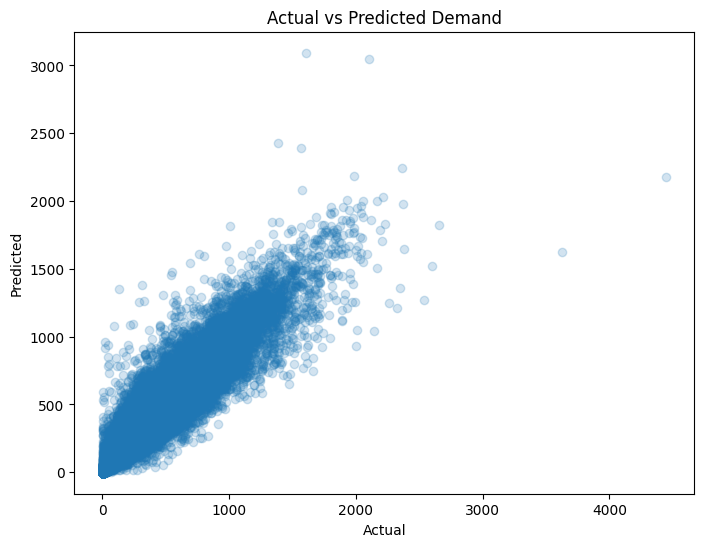

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Demand')

Our metrics tell us that our model's error is ~15.3% of average demand. This, combined with the very obvious correlation between actual and predicted demand, indicates strong overall model fit. There also appears to be greater variability in predictions at higher demand levels, although this may partly reflect fewer observations in that range.

**Evaluation Note**

The model is evaluated using MAE, RMSE, and MAE as a percentage of mean demand. MAE is useful because it describes the average prediction error in trips per zone-hour, while RMSE places more weight on larger errors during high-demand periods. MAE as a percentage of mean demand provides additional context for interpreting the size of the error.

One limitation is that the model is not compared against a simple naive baseline, such as predicting demand using the previous hour or the same hour from the previous week. Without that comparison, the metrics show the model's absolute error but do not fully show how much value the regression model adds beyond a simple historical-demand rule. Adding baseline comparisons would be a useful next step for evaluating whether the model improves meaningfully over simpler forecasting approaches.

Interpret feature importance:

In [ ]:
coefficients = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': model.coef_
}).sort_values(by='coefficient', key=abs, ascending=False)

coefficients[
    ~coefficients['feature'].str.contains('pickup_zone')
].sort_values(by='coefficient', key=abs, ascending=False).head(10)

,feature,coefficient
1,day_of_week,1.024114
4,prev_week_same_day_same_hour_demand,0.438738
2,prev_hour_demand,0.417428
3,prev_day_same_hour_demand,0.149579
0,hour,0.121547


In [ ]:
zone_coefs = coefficients[coefficients['feature'].str.contains('pickup_zone')]

print(zone_coefs['coefficient'].abs().mean())

0.31005738200545213


**Coefficient Interpretation Note**

The coefficient table should be interpreted directionally rather than as a strict feature-importance ranking. The variables are not all on the same scale, and pickup zone is represented using one-hot encoded dummy variables, so coefficient size alone does not perfectly measure which features are most important.

Still, the positive coefficients on previous-hour, previous-day, and previous-week demand suggest that recent and repeating demand patterns are useful forecasting signals. Hour and day of week add temporal context, while pickup zone helps account for differences across locations. Overall, the model supports the idea that hourly ride demand is influenced by both time-based patterns and location-specific demand behavior.

> ⚠️ **Important Limitation**  
> The model relies only on historical demand, time-based features, and pickup-zone information. It does not account for external factors such as weather, holidays, major events, transit disruptions, or airport-specific conditions, which may explain some of the larger errors observed during peak demand periods. Because this is a baseline linear model, the coefficients are useful for interpretation but should not be treated as a complete explanation of all factors driving NYC ride demand.

## Step 6: Feature Engineering for K-means clustering

Create time buckets:

In [ ]:
trips_cluster = (
    trips_enriched
    .withColumn('hour', F.hour('dropoff_timestamp'))
    .withColumn(
        'time_bucket',
        F.when(F.col('hour').between(5, 10), 'early_morning')
         .when(F.col('hour').between(11, 16), 'midday')
         .when(F.col('hour').between(17, 21), 'evening')
         .otherwise('late_night')
    )
    .withColumn(
        'is_weekend',
        F.when(F.dayofweek('dropoff_timestamp').isin([1,7]), 1).otherwise(0)
    )
)

Create distance buckets:

In [ ]:
trips_cluster = trips_cluster.withColumn(
    'distance_bucket',
    F.when(F.col('trip_distance') < 2, 'short')
     .when(F.col('trip_distance') < 6, 'med')
     .otherwise('long')
)

Aggregate to dropoff zone:

In [ ]:
zone_agg = (
    trips_cluster
    .groupBy('dropoff_zone')
    .agg(
        F.count('*').alias('total_dropoffs'),

        # time buckets
        F.sum(F.when(F.col('time_bucket') == 'early_morning', 1).otherwise(0)).alias('early_morning'),
        F.sum(F.when(F.col('time_bucket') == 'midday', 1).otherwise(0)).alias('midday'),
        F.sum(F.when(F.col('time_bucket') == 'evening', 1).otherwise(0)).alias('evening'),
        F.sum(F.when(F.col('time_bucket') == 'late_night', 1).otherwise(0)).alias('late_night'),

        # weekend
        F.sum('is_weekend').alias('weekend'),

        # distance buckets
        F.sum(F.when(F.col('distance_bucket') == 'short', 1).otherwise(0)).alias('short'),
        F.sum(F.when(F.col('distance_bucket') == 'med', 1).otherwise(0)).alias('med'),
        F.sum(F.when(F.col('distance_bucket') == 'long', 1).otherwise(0)).alias('long')
    )
)

Convert counts to percentages:

In [ ]:
zone_features = (
    zone_agg
    .withColumn('% early morning', F.col('early_morning') / F.col('total_dropoffs'))
    .withColumn('% midday', F.col('midday') / F.col('total_dropoffs'))
    .withColumn('% evening', F.col('evening') / F.col('total_dropoffs'))
    .withColumn('% late night', F.col('late_night') / F.col('total_dropoffs'))
    .withColumn('% weekend', F.col('weekend') / F.col('total_dropoffs'))
    .withColumn('% short', F.col('short') / F.col('total_dropoffs'))
    .withColumn('% med', F.col('med') / F.col('total_dropoffs'))
    .withColumn('% long', F.col('long') / F.col('total_dropoffs'))
)

Add dropoff share:

In [ ]:
total_trips = zone_agg.agg(F.sum('total_dropoffs')).collect()[0][0]

zone_features = zone_features.withColumn(
    'dropoff_share',
    F.col('total_dropoffs') / F.lit(total_trips)
)

Select final features:

In [ ]:
zone_features_final = zone_features.select(
    'dropoff_zone',
    '% early morning',
    '% midday',
    '% evening',
    '% late night',
    '% weekend',
    '% short',
    '% med',
    '% long',
    'dropoff_share'
)

## Step 7: Perform K-means clustering

Convert to Pandas:

In [ ]:
zone_features_pd = zone_features_final.toPandas()

Seperate features:

In [ ]:
X = zone_features_pd.drop(columns=['dropoff_zone'])

Standardize features:

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Choose number of clusters using elbow method:

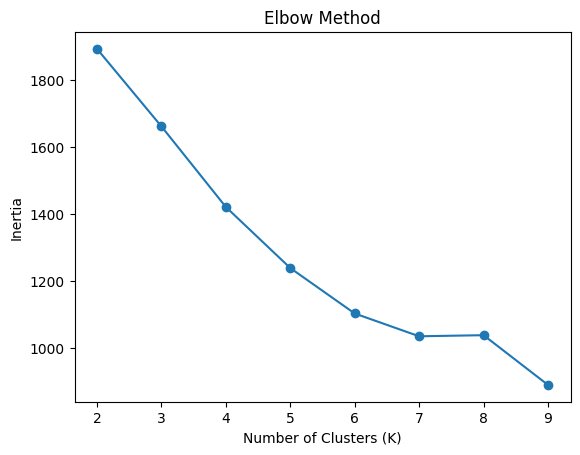

In [ ]:
from sklearn.cluster import KMeans

inertia = []

K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

**Choosing K**

The elbow plot does not show a perfectly clear elbow, which means there is not one obvious best number of clusters. Based on the curve, a range of roughly 5–6 clusters appears reasonable.

We selected K = 5 because it balances separation and interpretability. Using too few clusters would combine zones with meaningfully different behavior, while using too many clusters would create groups that are harder to explain in a short presentation. Since the purpose of this clustering step is business interpretation rather than prediction, interpretability was an important factor in the final choice.

Run final K-means:

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
zone_features_pd['cluster'] = kmeans.fit_predict(X_scaled)

Inspect clusters:

In [ ]:
cluster_summary = (
    zone_features_pd
    .drop(columns=['dropoff_zone'])
    .groupby('cluster')
    .mean()
)

print(cluster_summary)

         % early morning  % midday  % evening  % late night  % weekend  \
cluster                                                                  
0               0.164244  0.255729   0.314000      0.266027   0.334940   
1               0.266519  0.321541   0.247105      0.164836   0.307190   
2               0.237641  0.296260   0.276054      0.190045   0.281825   
3               0.324231  0.327431   0.205740      0.142598   0.275326   
4               0.400000  0.000000   0.000000      0.600000   0.000000   

          % short     % med    % long  dropoff_share  
cluster                                               
0        0.366784  0.427538  0.205678   4.507143e-03  
1        0.252292  0.417163  0.330545   1.275641e-03  
2        0.435687  0.367615  0.196698   4.134218e-03  
3        0.026649  0.109291  0.864060   2.094623e-02  
4        0.800000  0.000000  0.200000   1.707059e-08  


## Step 8: Interpret clusters

**Cluster 0:** Weekend & Night Activity Zones
- Higher share of weekend and evening/night activity
- Mix of short and medium trips
- Represents moderately active, leisure-oriented areas

**Cluster 1:** Balanced General-Purpose Zones
- Evenly distributed demand across time of day
- Slight emphasis on midday activity and medium-length trips
- Represents general-purpose zones without a dominant pattern

**Cluster 2:** Short-Distance Commute Zones
- Dominated by short-to-medium distance trips
- Demand is evenly distributed across time
- Likely reflects local movement and commuter-style travel

**Cluster 3:** High-Demand Long-Distance Hubs
- Highest-demand zones, capturing a large share of total trips
- Strongly dominated by long-distance travel (~86%)
- Activity is concentrated earlier in the day, with less nighttime demand

**Cluster 4:** Low-Volume Specialized Zones
- Extremely low-volume, highly specialized zone(s)
- Trips occur almost exclusively in early morning or late night
- Does not follow typical NYC demand patterns, indicating unique operational use

**Clustering Interpretation Note**

The cluster labels are descriptive summaries based on the average feature values within each group. They should be interpreted as behavioral segments rather than exact definitions of every zone in the cluster. Some individual zones may not perfectly match the cluster label, but the labels provide a useful high-level way to summarize common dropoff patterns across time of day, weekend activity, trip distance, and total dropoff share.

## Step 9: Export relevant data to csv files for downstream Power BI dashboard

In [ ]:
from google.colab import files

# Optional: set export folder
export_path = '/content/drive/My Drive/bia_678_final/data/exports'

# -----------------------------
# 1. zone_hour_actuals.csv
# -----------------------------
zone_hour_actuals_pd = (
    zone_hour_df
    .select(
        'date',
        'hour',
        'day_of_week',
        'pickup_zone',
        'trip_count'
    )
    .toPandas()
)

zone_hour_actuals_pd.to_csv(f'{export_path}/zone_hour_actuals.csv', index=False)


# -----------------------------
# 2. forecast_results.csv
# -----------------------------
# Rebuild results from the original non-one-hot dataframe so pickup_zone/date/hour are readable
forecast_results_pd = zone_hour_df_pd.sort_values(['date', 'hour']).iloc[split_index:].copy()

forecast_results_pd['actual'] = y_test.values
forecast_results_pd['predicted'] = y_pred
forecast_results_pd['absolute_error'] = abs(forecast_results_pd['actual'] - forecast_results_pd['predicted'])

forecast_results_pd = forecast_results_pd[
    [
        'date',
        'hour',
        'day_of_week',
        'pickup_zone',
        'actual',
        'predicted',
        'absolute_error',
        'prev_hour_demand',
        'prev_day_same_hour_demand',
        'prev_week_same_day_same_hour_demand'
    ]
]

forecast_results_pd.to_csv(f'{export_path}/forecast_results.csv', index=False)


# -----------------------------
# 3. cluster_assignments.csv
# -----------------------------
cluster_name_map = {
    0: 'Weekend & Night Activity Zones',
    1: 'Balanced General-Purpose Zones',
    2: 'Short-Distance Commute Zones',
    3: 'Long-Distance High-Demand Hubs',
    4: 'Low-Volume Specialized Zones'
}

zone_features_pd['cluster_name'] = zone_features_pd['cluster'].map(cluster_name_map)

cluster_assignments_pd = zone_features_pd[
    [
        'dropoff_zone',
        'cluster',
        'cluster_name',
        '% early morning',
        '% midday',
        '% evening',
        '% late night',
        '% weekend',
        '% short',
        '% med',
        '% long',
        'dropoff_share'
    ]
]

cluster_assignments_pd.to_csv(f'{export_path}/cluster_assignments.csv', index=False)


# -----------------------------
# 4. cluster_summary.csv
# -----------------------------
feature_cols = [
    '% early morning',
    '% midday',
    '% evening',
    '% late night',
    '% weekend',
    '% short',
    '% med',
    '% long',
    'dropoff_share'
]

cluster_summary_pd = (
    zone_features_pd
    .groupby(['cluster', 'cluster_name'])[feature_cols]
    .mean()
    .reset_index()
)

zone_counts_pd = (
    zone_features_pd
    .groupby(['cluster', 'cluster_name'])
    .size()
    .reset_index(name='zone_count')
)

cluster_summary_pd = cluster_summary_pd.merge(
    zone_counts_pd,
    on=['cluster', 'cluster_name'],
    how='left'
)

cluster_summary_pd.to_csv(f'{export_path}/cluster_summary.csv', index=False)


# -----------------------------
# 5. trip_type_hour_summary.csv
# -----------------------------
trip_type_hour_summary_pd = (
    trips_enriched
    .withColumn('hour', F.hour('pickup_timestamp'))
    .groupBy('hour', 'trip_type')
    .agg(F.count('*').alias('trip_count'))
    .orderBy('hour', 'trip_type')
    .toPandas()
)

trip_type_hour_summary_pd.to_csv(f'{export_path}/trip_type_hour_summary.csv', index=False)


# -----------------------------
# 6. pickup_borough_summary.csv
# -----------------------------
pickup_borough_summary_pd = (
    trips_enriched
    .filter(~F.col('pickup_borough').isin('EWR', 'Unknown', 'N/A'))
    .groupBy('pickup_borough', 'trip_type')
    .agg(F.count('*').alias('trip_count'))
    .orderBy('pickup_borough', 'trip_type')
    .toPandas()
)

pickup_borough_summary_pd.to_csv(f'{export_path}/pickup_borough_summary.csv', index=False)

# -----------------------------
# 7. zone_dimension.csv
# -----------------------------
# Distinct zone lookup table with borough and cluster assignment

zone_lookup_pd = (
    zones_df
    .select(
        F.col('LocationID').alias('zone_id'),
        F.col('Zone').alias('zone_name'),
        F.col('Borough').alias('borough'),
        F.col('service_zone').alias('service_zone')
    )
    .dropDuplicates(['zone_id'])
    .toPandas()
)

zone_cluster_pd = cluster_assignments_pd[
    [
        'dropoff_zone',
        'cluster',
        'cluster_name'
    ]
].drop_duplicates()

zone_dimension_pd = zone_lookup_pd.merge(
    zone_cluster_pd,
    left_on='zone_name',
    right_on='dropoff_zone',
    how='left'
)

zone_dimension_pd = zone_dimension_pd[
    [
        'zone_id',
        'zone_name',
        'borough',
        'service_zone',
        'cluster',
        'cluster_name'
    ]
]

zone_dimension_pd['cluster_name'] = zone_dimension_pd['cluster_name'].fillna('Not Clustered')

zone_dimension_pd.to_csv(f'{export_path}/zone_dimension.csv', index=False)

# -----------------------------
# 8. dashboard_demand_summary.csv
# -----------------------------
# Aggregated demand table for Power BI slicers:
# hour, time of day, zone, borough, and trip type

dashboard_demand_summary_spark = (
    trips_enriched
    .withColumn('year', F.year('pickup_timestamp'))
    .withColumn('month_num', F.month('pickup_timestamp'))
    .withColumn('month_name', F.date_format('pickup_timestamp', 'MMMM'))
    .withColumn('hour', F.hour('pickup_timestamp'))
    .withColumn('day_of_week', F.dayofweek('pickup_timestamp'))
    .withColumn(
        'time_bucket',
        F.when(F.col('hour').between(5, 10), 'Early Morning')
         .when(F.col('hour').between(11, 16), 'Midday')
         .when(F.col('hour').between(17, 21), 'Evening')
         .otherwise('Late Night')
    )
    .withColumn(
        'time_bucket_sort',
        F.when(F.col('time_bucket') == 'Early Morning', 1)
         .when(F.col('time_bucket') == 'Midday', 2)
         .when(F.col('time_bucket') == 'Evening', 3)
         .otherwise(4)
    )
    .groupBy(
        'year',
        'month_num',
        'month_name',
        'hour',
        'day_of_week',
        'time_bucket',
        'time_bucket_sort',
        'pickup_borough',
        'pickup_zone',
        'trip_type'
    )
    .agg(F.count('*').alias('trip_count'))
)

dashboard_demand_summary_pd = dashboard_demand_summary_spark.toPandas()

dashboard_demand_summary_pd.to_csv(f'{export_path}/dashboard_demand_summary.csv', index=False)

print('CSV exports complete.')

CSV exports complete.


## Step 10: Discuss limitations and potential future improvements

This project demonstrates an end-to-end pipeline for processing high-volume TLC trip data, aggregating demand to the zone-hour level, building an interpretable baseline forecasting model, and segmenting zones using K-means clustering. The results show clear temporal and geographic demand patterns, but several limitations should be considered.

First, the regression model relies on lag-demand features calculated from ordered rows within each pickup zone. If some zone-hour records are missing, these lag features may not always align perfectly to the previous hour, same hour yesterday, or same hour last week. A future version of the pipeline should create a complete pickup-zone × date × hour grid, fill missing demand values with zero, and then calculate lag features from that complete time series.

Second, the model uses a simplified time-based train/test split. This is more appropriate than a random split for forecasting, but a stronger evaluation design would use explicit date cutoffs, rolling forecast windows, or backtesting across multiple periods.

Third, the regression model is intended as an interpretable baseline rather than a final production model. Linear regression is useful for explaining directional relationships, but it may not fully capture nonlinear demand patterns, peak-period behavior, or unusual events. Future work could compare this model against naive historical baselines, tree-based models, gradient boosting, Poisson regression, or time-series models.

Finally, the current feature set is limited to trip history, time, location, and engineered lag features. Demand could likely be improved by adding external variables such as weather, holidays, major events, transit disruptions, or airport activity. These additions would help the model better explain unusual demand spikes that cannot be captured from historical trip patterns alone.